In [35]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url) 

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Data Preparation

In [36]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [37]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [38]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score'] 
categorical = ['lead_source', 'industry', 'employment_status', 'location']

In [39]:
df[numerical] = df[numerical].fillna(0.0) 
df[categorical] = df[categorical].fillna('NA')

In [40]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

### Question 1

In [41]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

### Question 2 

In [42]:
df[numerical].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


<Axes: >

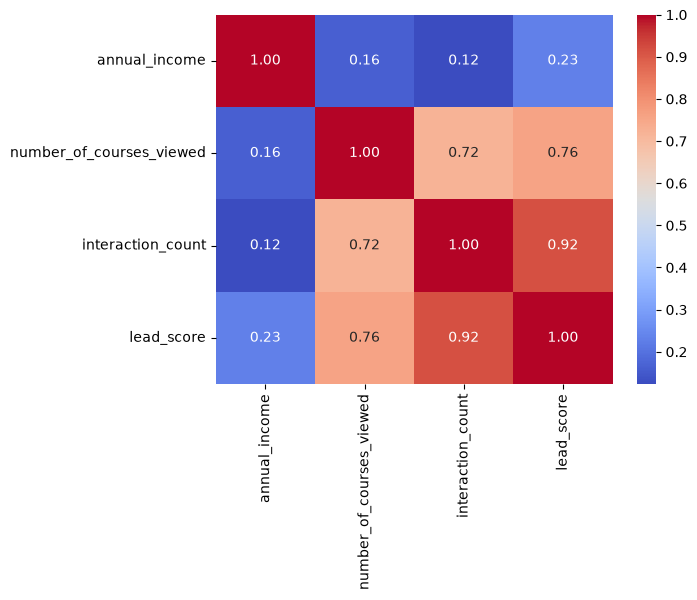

In [43]:
sns.heatmap(df[numerical].corr(), annot=True, fmt='.2f', cmap='coolwarm')

### Split the data

In [44]:
from sklearn.model_selection import train_test_split

In [45]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42)

In [46]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 3

In [34]:
from sklearn.metrics import mutual_info_score

In [49]:
def mutual_info_churn_score(series): 
    return mutual_info_score(series, y_train)

In [50]:
mi = df_train[categorical].apply(mutual_info_churn_score) 
round(mi.sort_values(ascending=False),2)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

### Question 4

In [51]:
from sklearn.feature_extraction import DictVectorizer

In [52]:
dv = DictVectorizer(sparse=False)

In [63]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts) 
val_dicts = df_val[categorical + numerical].to_dict(orient='records') 
X_val = dv.transform(val_dicts) 
test_dicts = df_test[categorical + numerical].to_dict(orient='records') 
X_test = dv.transform(test_dicts) 


In [64]:
from sklearn.linear_model import LogisticRegression

In [66]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42) 
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [67]:
y_pred = model.predict_proba(X_val)[:, 1]
converted_decision = (y_pred >= 0.5)

In [70]:

round((y_val == converted_decision).mean(),2)

np.float64(0.64)

### Question 5

In [ ]:
def train_and_evaluate(features,):
    dv = DictVectorizer(sparse=False)

    train_dicts = df_train[features].to_dict(orient='records')
    X_train = dv.fit_transform(train_dicts)

    val_dicts = df_val[features].to_dict(orient='records')
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    return ((y_pred >= 0.5) == y_val).mean()

In [72]:
all_features = categorical + numerical
original_acc = train_and_evaluate(all_features)
print('Original:', original_acc)

for feature in all_features:
    features = [f for f in all_features if f != feature]
    acc = train_and_evaluate(features)
    diff = original_acc - acc
    print(f'{feature:28s} acc={acc:.4f}  diff={diff:.4f}')

Original: 0.645
lead_source                  acc=0.6420  diff=0.0030
industry                     acc=0.6450  diff=0.0000
employment_status            acc=0.6450  diff=0.0000
location                     acc=0.6450  diff=0.0000
annual_income                acc=0.7240  diff=-0.0790
number_of_courses_viewed     acc=0.6430  diff=0.0020
interaction_count            acc=0.6010  diff=0.0440
lead_score                   acc=0.6440  diff=0.0010


### Question 6 

In [74]:
def train_and_evaluate_reg(features,c=1.0):
    dv = DictVectorizer(sparse=False)

    train_dicts = df_train[features].to_dict(orient='records')
    X_train = dv.fit_transform(train_dicts)

    val_dicts = df_val[features].to_dict(orient='records')
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    return ((y_pred >= 0.5) == y_val).mean()

In [75]:
for c in [0.000001, 0.00001, 0.0001, 0.001]: 
    acc = train_and_evaluate_reg(all_features, c=c)
    print(f"C={c}: {round(acc, 3)}") 

    

C=1e-06: 0.598
C=1e-05: 0.598
C=0.0001: 0.613
C=0.001: 0.645
